# McGill COMP551, MINI-PROJECT 3: Odd-One-Out Image Groups
Student names (IDs) - **Group 58**
*   Hadi El Nawfal (261328930)
*   Andrea Gomez (261273588)
*   Bora Sanal (261313803)

# Kaggle Competition
Training and test data are available as part of the assignment in the `datasets` folder. To participate in the competition you should upload a CSV file containing your predicted labels for the entire test data to Kaggle.

The test data is divided in half. You receive the correct labels for the first half (in the `datasets` folder), so that you can evaluate your model in this notebook on that part of the test set. You then submit your solution for the entire test set to Kaggle. The final evaluation is based on your predictions for the second half of the test set (private leaderboard). We have step-by-step explanation in the final section of this notebook.


# Report
The purpose of this notebook is for you to provide a concise high level code of your methodology. That is, you need to include all steps necessary to reproduce your results. Please include a high-level explanation of the implementation so that we can understand what you're trying to achieve in each piece of the code. You can import python code here if needed, in order to keep the notebook concise.

**Note:** You need to submit this notebook where you have run all the cells as part of the assignment. **We should not need to rerun your code since this can take a long time.**


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Step 1 — The Dataset
Use the following code to load the data using the npy files. We have **3,000 training examples**, where each example is a group of **5 grayscale images** (each 32×32). In each group:
- **4 images** share a hidden common property, and
- **1 image** is the **outlier**.

You do **not** have access to the underlying attributes. Your task is to learn to identify the **index** of the outlier image (a 5-class classification problem, with labels in {0, 1, 2, 3, 4}). The label is printed above each group shown below.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

x = np.load('/content/drive/MyDrive/x_train.npy')  # (3000, 5, 32, 32) — 3000 groups of 5 images each
y = np.load('/content/drive/MyDrive/y_train.npy')  # (3000,) — index of the outlier image in each group (0-4)  # (3000,) — index of the outlier image in each group (0-4)

print(f'Training set: {x.shape[0]} groups, each with {x.shape[1]} images of size {x.shape[2]}x{x.shape[3]}')
print(f'Labels: values in {np.unique(y)}')


Training set: 3000 groups, each with 5 images of size 32x32
Labels: values in [0 1 2 3 4]


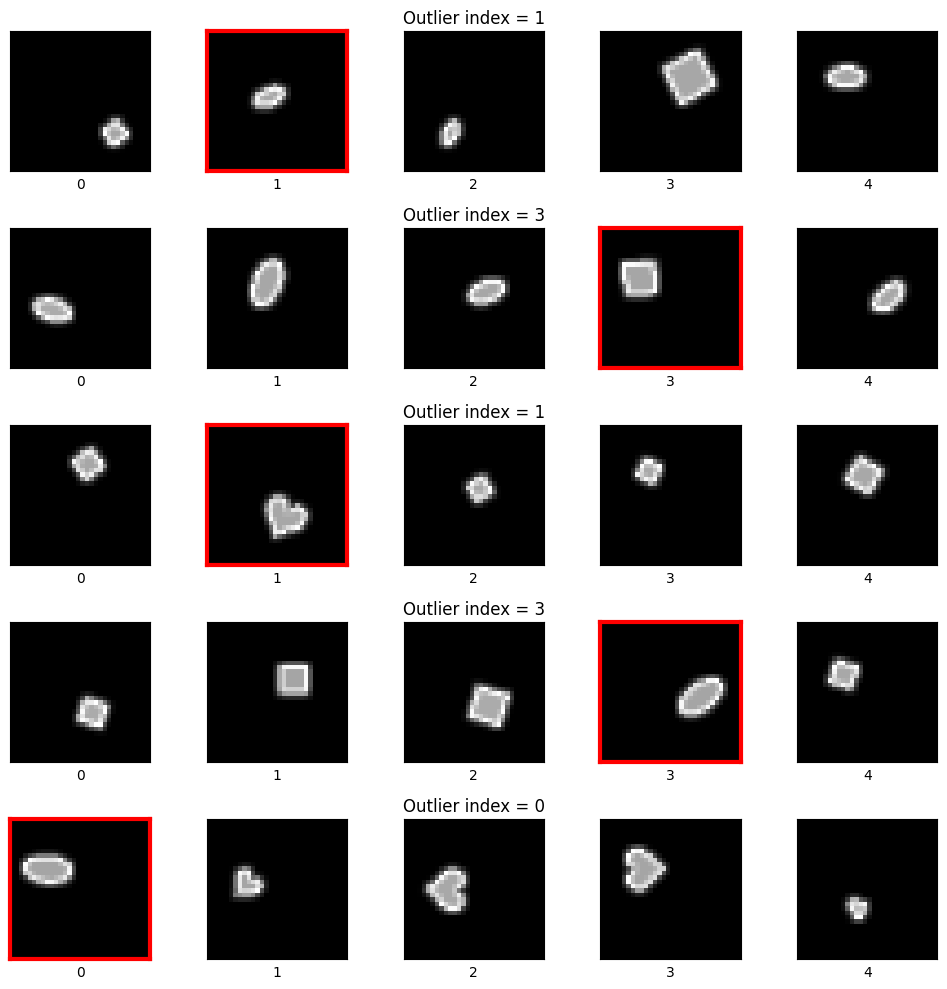

In [ ]:
def plot_groups(x, y, num_groups=5):
    fig, axes = plt.subplots(num_groups, 5, figsize=(10, 2 * num_groups))

    if num_groups == 1:
        axes = axes.reshape(1, -1)

    for i in range(num_groups):
        # label for the whole group
        axes[i, 2].set_title(f"Outlier index = {y[i]}", fontsize=12)

        for j in range(5):
            axes[i, j].imshow(x[i, j], cmap='gray')
            axes[i, j].set_xticks([])
            axes[i, j].set_yticks([])
            axes[i, j].set_xlabel(j)

            if j == y[i]:
                for spine in axes[i, j].spines.values():
                    spine.set_edgecolor('red')
                    spine.set_linewidth(3)

    plt.tight_layout()
    plt.show()

plot_groups(x, y, num_groups=5)

## Step 2 — Example: Logistic Regression Baseline
Below we apply a simple logistic regression to the flattened input as a demonstration. This model treats the entire group of 5 images as one flat vector and does not use any deep learning.

Note that **random chance** for this 5-class problem is **20%** (1/5).
As you can see, the logistic regression baseline performs close to random chance — you are expected to do significantly better using a deep learning model implemented in PyTorch (or Jax/TensorFlow).

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
import warnings
warnings.filterwarnings('ignore')

features = x.reshape(x.shape[0], -1)  # flatten each group of 5 images into a single vector
labels = y

x_train, x_val, y_train, y_val = train_test_split(features, labels, test_size=0.33, random_state=42)

clf = LogisticRegression(max_iter=1000)
clf.fit(x_train, y_train)

predictions = clf.predict(x_val)
accuracy = accuracy_score(y_val, predictions)
print(f'The validation accuracy of the baseline model is {accuracy * 100:.2f}%')

The validation accuracy of the baseline model is 19.39%


## Step 3 — Your Model
This is the main part of your report. Provide your model implementation, training code, and explanation below. Details should include the architecture, choice of hyperparameters, and any preprocessing or augmentation you applied. If you performed a hyperparameter search, explain it here.

**Important:** Your model must have at most **25,000** trainable parameters. You **must** uncomment and run the cell below to print and verify the parameter count. This count must also appear in your report.

In [ ]:
# ════════════════════════════════════════════════════════
# ODD-ONE-OUT CLASSIFIER V11
# ════════════════════════════════════════════════════════

#Snippet 1: Imports & Seeds
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.optim.swa_utils import AveragedModel, SWALR, update_bn
from torch.utils.data import Dataset, DataLoader, TensorDataset
import numpy as np
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score
import random, copy, warnings
warnings.filterwarnings('ignore')

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.deterministic = True

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")



#Snippet 2: Preprocessing
def preprocess_single_image(img, out_size=32, inner_size=26,
                             thr_ratio=0.18, min_thr=0.04, margin=1):
    t  = torch.tensor(img, dtype=torch.float32)
    mx = float(t.max())
    if mx <= 0: return t.numpy()
    thr  = max(min_thr, thr_ratio * mx)
    mask = t > thr
    if mask.sum() == 0: return t.numpy()
    ys, xs = mask.nonzero(as_tuple=True)
    y0 = max(int(ys.min()) - margin, 0)
    y1 = min(int(ys.max()) + 1 + margin, t.shape[0])
    x0 = max(int(xs.min()) - margin, 0)
    x1 = min(int(xs.max()) + 1 + margin, t.shape[1])
    crop  = t[y0:y1, x0:x1]
    h, w  = crop.shape
    scale = inner_size / max(h, w)
    new_h = max(1, int(round(h * scale)))
    new_w = max(1, int(round(w * scale)))
    crop  = F.interpolate(
        crop.unsqueeze(0).unsqueeze(0),
        size=(new_h, new_w), mode='bilinear', align_corners=False
    ).squeeze()
    canvas = torch.zeros((out_size, out_size), dtype=torch.float32)
    top  = (out_size - new_h) // 2
    left = (out_size - new_w) // 2
    canvas[top:top + new_h, left:left + new_w] = crop
    return canvas.numpy()


def preprocess_groups(x, out_size=32, inner_size=26,
                      thr_ratio=0.18, min_thr=0.04, margin=1):
    out = np.empty_like(x, dtype=np.float32)
    for i in range(x.shape[0]):
        for j in range(x.shape[1]):
            out[i, j] = preprocess_single_image(
                x[i, j], out_size, inner_size, thr_ratio, min_thr, margin)
    return out


#Snippet 3: Dataset
class OddOneOutDataset(Dataset):
    def __init__(self, x, y, augment=False):
        self.x       = torch.tensor(x, dtype=torch.float32)
        self.y       = torch.tensor(y, dtype=torch.long)
        self.augment = augment

    def __len__(self): return len(self.y)

    def __getitem__(self, idx):
        group = self.x[idx].clone()
        label = self.y[idx].item()

        if self.augment:
            # 1) Permutation: shuffle image order, relabel
            if random.random() < 0.5:
                perm  = torch.randperm(5)
                group = group[perm]
                label = int((perm == label).nonzero(as_tuple=True)[0].item())

            # 2) Geometric: same transform for all 5
            if random.random() < 0.5: group = group.flip(-1)
            if random.random() < 0.5: group = group.flip(-2)
            k = random.randint(0, 3)
            if k > 0: group = torch.rot90(group, k, dims=(-2, -1))

            # 3) Shared random erasing: same patch for all 5
            if random.random() < 0.15:
                eh = random.randint(2, 5)
                ew = random.randint(2, 5)
                ey = random.randint(0, group.shape[-2] - eh)
                ex = random.randint(0, group.shape[-1] - ew)
                group[:, ey:ey + eh, ex:ex + ew] = 0.0

            # 4) Shared Gaussian noise: same field for all 5
            if random.random() < 0.10:
                noise = torch.randn(1, group.shape[-2], group.shape[-1]) * 0.02
                group = group + noise

        return group, torch.tensor(label, dtype=torch.long)

#Snippet 4: Model (24,997 params)
class DepthwiseSeparableConv(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.depthwise = nn.Conv2d(in_ch, in_ch, 3, padding=1, groups=in_ch, bias=False)
        self.bn_dw     = nn.BatchNorm2d(in_ch)
        self.pointwise = nn.Conv2d(in_ch, out_ch, 1, bias=False)
        self.bn_pw     = nn.BatchNorm2d(out_ch)

    def forward(self, x):
        x = F.relu(self.bn_dw(self.depthwise(x)))
        x = F.relu(self.bn_pw(self.pointwise(x)))
        return x


class SEBlock(nn.Module):
    def __init__(self, channels, mid=8):
        super().__init__()
        self.fc1 = nn.Linear(channels, mid)
        self.fc2 = nn.Linear(mid, channels)

    def forward(self, x):
        w = x.mean(dim=(-2, -1))
        w = torch.sigmoid(self.fc2(F.relu(self.fc1(w))))
        return x * w.unsqueeze(-1).unsqueeze(-1)


class ImageEncoder(nn.Module):
    def __init__(self, emb_dim=56):
        super().__init__()
        self.conv1  = nn.Conv2d(1, 16, 5, padding=2, bias=False)
        self.bn1    = nn.BatchNorm2d(16)
        self.block2 = DepthwiseSeparableConv(16, 28)
        self.block3 = DepthwiseSeparableConv(28, 40)
        self.block4 = DepthwiseSeparableConv(40, 48)
        self.se     = SEBlock(48, mid=8)
        self.fc     = nn.Linear(48, emb_dim)

    def forward(self, x):
        x = F.relu(self.bn1(self.conv1(x)))
        x = F.max_pool2d(x, 2)
        x = self.block2(x); x = F.max_pool2d(x, 2)
        x = self.block3(x); x = F.max_pool2d(x, 2)
        x = self.block4(x)
        x = self.se(x)
        x = F.adaptive_avg_pool2d(x, 1).flatten(1)
        return self.fc(x)


class CrossImageAttention(nn.Module):
    def __init__(self, emb_dim=56, head_dim=16, attn_dropout=0.05):
        super().__init__()
        self.head_dim = head_dim
        self.scale    = head_dim ** -0.5
        self.W_q      = nn.Linear(emb_dim, head_dim, bias=False)
        self.W_k      = nn.Linear(emb_dim, head_dim, bias=False)
        self.W_v      = nn.Linear(emb_dim, head_dim, bias=False)
        self.W_o      = nn.Linear(head_dim, emb_dim, bias=False)
        self.attn_drop = nn.Dropout(attn_dropout)
        self.ln        = nn.LayerNorm(emb_dim)

    def forward(self, z, return_weights=False):
        B, G, D = z.shape
        Q = self.W_q(z); K = self.W_k(z); V = self.W_v(z)
        attn = torch.bmm(Q, K.transpose(1, 2)) * self.scale
        diag_mask = torch.eye(G, device=z.device, dtype=torch.bool).unsqueeze(0)
        attn = attn.masked_fill(diag_mask, -1e9)
        attn = self.attn_drop(F.softmax(attn, dim=-1))
        out  = torch.bmm(attn, V)
        z_out = self.ln(z + self.W_o(out))
        if return_weights:
            return z_out, attn
        return z_out


class OddOneOutNet(nn.Module):
    def __init__(self, emb_dim=56, head_dim=16, rel_hidden=40,
                 score_hidden=16, dropout=0.10, attn_dropout=0.05):
        super().__init__()
        self.encoder      = ImageEncoder(emb_dim)
        self.attention    = CrossImageAttention(emb_dim, head_dim, attn_dropout)
        self.relation_mlp = nn.Sequential(
            nn.Linear(emb_dim * 4, rel_hidden), nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(rel_hidden, rel_hidden), nn.ReLU(),
        )
        # attn_mean(40) + max(40) + std(40) + 4 proto scalars = 124
        self.scorer = nn.Sequential(
            nn.Linear(rel_hidden * 3 + 4, score_hidden), nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(score_hidden, 1)
        )

    def forward(self, x):
        B, G, H, W = x.shape
        z = self.encoder(x.view(B * G, 1, H, W)).view(B, G, -1)
        z = F.normalize(z, dim=-1)
        z, attn = self.attention(z, return_weights=True)

        logits = []
        for i in range(G):
            zi     = z[:, i, :]
            idx    = [j for j in range(G) if j != i]
            others = z[:, idx, :]

            rels = []
            for j in idx:
                zj   = z[:, j, :]
                pair = torch.cat([zi, zj, torch.abs(zi - zj), zi * zj], dim=1)
                rels.append(self.relation_mlp(pair))
            rs = torch.stack(rels, dim=1)   # (B, 4, 40)

            w         = attn[:, i, idx].unsqueeze(-1)
            w         = w / (w.sum(dim=1, keepdim=True) + 1e-8)
            attn_mean = (rs * w).sum(dim=1)
            max_rel   = rs.max(dim=1).values
            std_rel   = rs.std(dim=1, unbiased=False)

            proto     = others.mean(dim=1)
            cos_proto = F.cosine_similarity(zi, proto, dim=1, eps=1e-8).unsqueeze(1)
            l2_proto  = ((zi - proto) ** 2).mean(dim=1, keepdim=True)
            cos_others = F.cosine_similarity(zi.unsqueeze(1), others, dim=2, eps=1e-8)
            mean_cos  = cos_others.mean(dim=1, keepdim=True)
            std_cos   = cos_others.std(dim=1, keepdim=True, unbiased=False)

            agg = torch.cat([attn_mean, max_rel, std_rel,
                             cos_proto, l2_proto, mean_cos, std_cos], dim=1)
            logits.append(self.scorer(agg))

        return torch.cat(logits, dim=1)


#Snippet 5: Verify parameter count
_m = OddOneOutNet()
_p = sum(p.numel() for p in _m.parameters() if p.requires_grad)
print(f"Trainable parameters: {_p:,}  (budget: 25,000)")
assert _p <= 25_000, f"Over budget: {_p:,}"
print("✓ Within 25k budget\n")
for name, sub in [("encoder", _m.encoder), ("attention", _m.attention),
                  ("relation_mlp", _m.relation_mlp), ("scorer", _m.scorer)]:
    sp = sum(p.numel() for p in sub.parameters() if p.requires_grad)
    print(f"  {name:20s}: {sp:>6,}")
del _m


#Snippet 6: Load & preprocess
print("\nLoading and preprocessing data...")
x_train_raw = np.load('/content/drive/MyDrive/x_train.npy').astype(np.float32) / 255.0
y_all       = np.load('/content/drive/MyDrive/y_train.npy')
x_test_raw  = np.load('/content/drive/MyDrive/x_test.npy').astype(np.float32) / 255.0
y_test_pub  = np.load('/content/drive/MyDrive/y_test.npy')

print("Preprocessing...")
x_all     = preprocess_groups(x_train_raw)
x_test_pp = preprocess_groups(x_test_raw)

mean = x_all.mean(); std = x_all.std()
x_all     = (x_all     - mean) / (std + 1e-8)
x_test_pp = (x_test_pp - mean) / (std + 1e-8)

x_test_eval = x_test_pp[:1000]
print(f"Train: {x_all.shape}  |  Test: {x_test_pp.shape}")

#Snippet 7: Training function
def train_one_fold(x_tr, y_tr, x_vl, y_vl, seed,
                   num_epochs=150, patience=40,
                   lr=2.0e-3, wd=4e-4, bs=64,
                   swa_start_frac=0.65,       # V11: earlier than V10's 0.75
                   label_smoothing=0.08,       # V11: up from V10's 0.05
                   dropout=0.10):

    torch.manual_seed(seed)
    model     = OddOneOutNet(dropout=dropout).to(device)
    swa_model = AveragedModel(model)

    criterion    = nn.CrossEntropyLoss(label_smoothing=label_smoothing)
    optimizer    = optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
    train_ds     = OddOneOutDataset(x_tr, y_tr, augment=True)
    val_ds       = OddOneOutDataset(x_vl, y_vl, augment=False)
    bn_ds        = OddOneOutDataset(x_tr, y_tr, augment=False)
    train_loader = DataLoader(train_ds, batch_size=bs, shuffle=True,
                              drop_last=True, num_workers=0)
    val_loader   = DataLoader(val_ds, batch_size=256, shuffle=False)
    bn_loader    = DataLoader(bn_ds,  batch_size=bs,  shuffle=False)

    swa_start = int(num_epochs * swa_start_frac)

    scheduler = optim.lr_scheduler.OneCycleLR(
        optimizer, max_lr=lr, epochs=swa_start,
        steps_per_epoch=len(train_loader),
        pct_start=0.25, div_factor=15, final_div_factor=300
    )
    swa_scheduler = SWALR(optimizer, swa_lr=3e-4, anneal_epochs=8)

    best_acc, best_state, wait = 0.0, None, 0
    swa_active = False

    for ep in range(num_epochs):
        model.train()
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad(set_to_none=True)
            loss = criterion(model(xb), yb)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            if ep < swa_start:
                scheduler.step()

        if ep >= swa_start:
            swa_model.update_parameters(model)
            swa_scheduler.step()
            swa_active = True

        model.eval()
        vc, vt = 0, 0
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(device), yb.to(device)
                vc += (model(xb).argmax(1) == yb).sum().item()
                vt += yb.size(0)
        vacc = vc / vt

        if vacc > best_acc:
            best_acc, best_state, wait = vacc, copy.deepcopy(model.state_dict()), 0
        else:
            wait += 1
            if wait >= patience and ep >= swa_start:
                break

    if swa_active:
        update_bn(bn_loader, swa_model, device=device)
        swa_model.eval()
        vc, vt = 0, 0
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(device), yb.to(device)
                vc += (swa_model(xb).argmax(1) == yb).sum().item()
                vt += yb.size(0)
        swa_acc = vc / vt
        print(f"    Ckpt: {best_acc*100:.2f}%  |  SWA: {swa_acc*100:.2f}%", end="")
        if swa_acc >= best_acc:
            print("  → SWA")
            return swa_model.module, swa_acc
        else:
            print("  → Ckpt")
            model.load_state_dict(best_state); model.eval()
            return model, best_acc
    else:
        model.load_state_dict(best_state); model.eval()
        return model, best_acc


#Snippet 8: Multi-seed 5-fold ensemble
#V10: 3 seeds 18 models
#V11: 5 seeds 30 models
#Each seed gives genuinely different models (init + fold splits differ).

ENSEMBLE_SEEDS = [42, 7, 123, 17, 99]   # 5 seeds × 5 folds = 25 fold models
N_FOLDS        = 5

all_fold_models   = []
all_fold_val_accs = []

for run_seed in ENSEMBLE_SEEDS:
    print(f"\n{'#'*50}\nSEED {run_seed}\n{'#'*50}")
    skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=run_seed)
    for fold_idx, (train_idx, val_idx) in enumerate(skf.split(x_all, y_all)):
        print(f"\n  Fold {fold_idx+1}/{N_FOLDS}  (seed={run_seed})")
        model, val_acc = train_one_fold(
            x_all[train_idx], y_all[train_idx],
            x_all[val_idx],   y_all[val_idx],
            seed=run_seed * 100 + fold_idx
        )
        all_fold_models.append(model)
        all_fold_val_accs.append(val_acc)
        print(f"  ✓ val: {val_acc*100:.2f}%")

print(f"\n{'='*50}")
print(f"{len(all_fold_models)} FOLD MODELS")
print(f"  Mean val: {np.mean(all_fold_val_accs)*100:.2f}%  |  Best: {np.max(all_fold_val_accs)*100:.2f}%")
print(f"{'='*50}")

#Snippet 9: Full-data models (one per seed = 5 models)
full_models = []
for run_seed in ENSEMBLE_SEEDS:
    print(f"\nFull-data model (seed={run_seed})...")
    torch.manual_seed(run_seed + 999)
    fm     = OddOneOutNet(dropout=0.10).to(device)
    swa_fm = AveragedModel(fm)
    fl     = DataLoader(OddOneOutDataset(x_all, y_all, augment=True),
                        batch_size=64, shuffle=True, drop_last=True)
    bnl    = DataLoader(OddOneOutDataset(x_all, y_all, augment=False),
                        batch_size=64, shuffle=False)
    opt    = optim.AdamW(fm.parameters(), lr=2.0e-3, weight_decay=4e-4)
    sch    = optim.lr_scheduler.CosineAnnealingLR(opt, T_max=160, eta_min=1e-5)
    swa_sch = SWALR(opt, swa_lr=3e-4, anneal_epochs=8)
    crit   = nn.CrossEntropyLoss(label_smoothing=0.08)
    SWA_ST = 100   # start SWA at epoch 100/160

    for ep in range(160):
        fm.train()
        for xb, yb in fl:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad(set_to_none=True)
            crit(fm(xb), yb).backward()
            torch.nn.utils.clip_grad_norm_(fm.parameters(), 1.0)
            opt.step()
        if ep >= SWA_ST:
            swa_fm.update_parameters(fm); swa_sch.step()
        else:
            sch.step()

    update_bn(bnl, swa_fm, device=device)
    swa_fm.eval()
    full_models.append(swa_fm)
    print("  ✓ ready")

#Snippet 10: parameter count
base   = all_fold_models[0]
base_m = base.module if hasattr(base, 'module') else base
total_params = sum(p.numel() for p in base_m.parameters() if p.requires_grad)
print(f"\nTotal trainable parameters: {total_params:,}")
assert total_params <= 25_000, f"Over budget! {total_params:,}"
print(f"Ensemble: {len(all_fold_models)} fold + {len(full_models)} full = "
      f"{len(all_fold_models)+len(full_models)} total models")


#Snippet 11: Inference: 8-variant TTA + squared val-acc weights
#These 8 variants are the complete D4 dihedral group of the square
#(all symmetry-preserving transforms)
#Squared weights sharpen the weighting toward better fold models.

def predict_logits(model, x_t, bs=256):
    out = []
    with torch.no_grad():
        for (xb,) in DataLoader(TensorDataset(x_t), batch_size=bs):
            out.append(model(xb.to(device)).cpu())
    return torch.cat(out, 0)


def get_tta_variants(x_t):
    """8 variants = full D4 dihedral group (exhaustive for squares)."""
    variants = []
    for k in range(4):
        rot = torch.rot90(x_t, k, dims=(-2, -1))
        variants.append(rot)
        variants.append(rot.flip(-1))
    return variants


def ensemble_tta_predict(models, x_np, weights=None):
    x_t      = torch.tensor(x_np, dtype=torch.float32)
    variants = get_tta_variants(x_t)
    if weights is None:
        weights = np.ones(len(models)) / len(models)
    weights = np.asarray(weights, dtype=np.float32)
    weights = weights / weights.sum()
    all_logits = []
    for m, w in zip(models, weights):
        m.eval()
        for xv in variants:
            all_logits.append(predict_logits(m, xv) * float(w))
    return torch.stack(all_logits, 0).mean(0).argmax(1).numpy()


def ensemble_predict(models, x_np, weights=None):
    x_t = torch.tensor(x_np, dtype=torch.float32)
    if weights is None:
        weights = np.ones(len(models)) / len(models)
    weights = np.asarray(weights, dtype=np.float32)
    weights = weights / weights.sum()
    logits = [predict_logits(m.eval(), x_t) * float(w)
              for m, w in zip(models, weights)]
    return torch.stack(logits, 0).sum(0).argmax(1).numpy()



#Snippet 12: Evaluate on public test set
all_models = all_fold_models + full_models

#Squared val-acc weights for fold models (sharpens toward better models)
fold_w_sq  = np.array(all_fold_val_accs, dtype=np.float32) ** 2
mean_fold_w = float(fold_w_sq.mean())
full_w      = np.full(len(full_models), mean_fold_w, dtype=np.float32)
all_weights  = np.concatenate([fold_w_sq, full_w])
all_weights  = all_weights / all_weights.sum()

print(f"\nEnsemble: {len(all_models)} models × 8 TTA = {len(all_models)*8} forward passes\n")

p1 = ensemble_predict(all_fold_models, x_test_eval)
print(f"25 folds (uniform, no TTA):      {accuracy_score(y_test_pub, p1)*100:.2f}%")

p2 = ensemble_tta_predict(all_fold_models, x_test_eval)
print(f"25 folds (uniform, 8-TTA):       {accuracy_score(y_test_pub, p2)*100:.2f}%")

p3 = ensemble_tta_predict(all_fold_models, x_test_eval, weights=fold_w_sq)
print(f"25 folds (sq-weighted, 8-TTA):   {accuracy_score(y_test_pub, p3)*100:.2f}%")

p4 = ensemble_tta_predict(all_models, x_test_eval, weights=all_weights)
print(f"All 30 (sq-weighted, 8-TTA):     {accuracy_score(y_test_pub, p4)*100:.2f}%")



#Snippet 13: public accuracy
your_predictions = ensemble_tta_predict(all_models, x_test_eval, weights=all_weights)
your_accuracy    = accuracy_score(y_test_pub, your_predictions)
print(f'\nPublic test accuracy (must match Kaggle): {your_accuracy * 100:.2f}%')

#Snippet 14: Kaggle CSV
import pandas as pd
full_preds = ensemble_tta_predict(all_models, x_test_pp, weights=all_weights)
pd.DataFrame({
    'Id':       np.arange(len(full_preds)).astype(str),
    'Category': full_preds.astype(str)
}).to_csv('predicted_labels.csv', index=False)
print("Saved 2000 predictions to predicted_labels.csv")

print(f"\n{'='*55}")
print(f" FINAL SUMMARY — V11")
print(f"{'='*55}")
print(f"  Architecture:    identical to V10 (maxed at 24,997 params)")
print(f"  Params:          {total_params:,} / 25,000")
print(f"  Seeds:           5  (V10 had 3)  → 25 fold + 5 full = 30 models")
print(f"  SWA start:       65% of epochs  (V10 was 75%)")
print(f"  Label smoothing: 0.08  (V10 was 0.05)")
print(f"  Weights:         val_acc²  (V10 used val_acc)")
print(f"  TTA:             8 variants (D4 dihedral — exhaustive)")
print(f"  Total fwd passes:{len(all_models)*8} per test sample")
print(f"  Mean fold val:   {np.mean(all_fold_val_accs)*100:.2f}%")
print(f"  Public test:     {your_accuracy*100:.2f}%")
print(f"{'='*55}")

Device: cuda
Trainable parameters: 24,997  (budget: 25,000)
✓ Within 25k budget

  encoder             :  8,644
  attention           :  3,696
  relation_mlp        : 10,640
  scorer              :  2,017

Loading and preprocessing data...
Preprocessing...
Train: (3000, 5, 32, 32)  |  Test: (2000, 5, 32, 32)

##################################################
SEED 42
##################################################

  Fold 1/5  (seed=42)
    Ckpt: 89.17%  |  SWA: 88.17%  → Ckpt
  ✓ val: 89.17%

  Fold 2/5  (seed=42)
    Ckpt: 91.00%  |  SWA: 90.67%  → Ckpt
  ✓ val: 91.00%

  Fold 3/5  (seed=42)
    Ckpt: 90.50%  |  SWA: 89.33%  → Ckpt
  ✓ val: 90.50%

  Fold 4/5  (seed=42)
    Ckpt: 91.83%  |  SWA: 91.00%  → Ckpt
  ✓ val: 91.83%

  Fold 5/5  (seed=42)
    Ckpt: 90.00%  |  SWA: 89.17%  → Ckpt
  ✓ val: 90.00%

##################################################
SEED 7
##################################################

  Fold 1/5  (seed=7)
    Ckpt: 91.33%  |  SWA: 90.50%  → Ckpt
  ✓ va

## Step 4 — Accuracy Metrics and CSV Submission to Kaggle
At minimum, you **must** report in your submitted notebook:
1. The **number of trainable parameters** (printed in Step 3 above).
2. Your accuracy on the **first half of the test set** (public leaderboard).

**This accuracy must match your public leaderboard score on Kaggle.** If it does not, your leaderboard submission is discarded.

Below we show this evaluation for the logistic regression baseline. Note that the baseline accuracy is close to **random chance (20%)** — you should aim to do much better.

In [ ]:
# Note: Step 4 and Generating CSV for Kaggle are done under step 3, so we commented this out.
# # ════════════════════════════════════════════════════════
# # PUBLIC TEST EVALUATION
# # ════════════════════════════════════════════════════════
# x_test = np.load('/content/drive/MyDrive/x_test.npy').astype(np.float32) / 255.0
# x_test = (x_test - mean) / (std + 1e-8)
# x_test_half = x_test[:1000]
# y_test_half = np.load('/content/drive/MyDrive/y_test.npy')

# print(f"Test: {x_test.shape[0]} groups (public: {x_test_half.shape[0]}, private: {x_test.shape[0]-x_test_half.shape[0]})")

# # Compare: single model vs ensemble vs ensemble+TTA
# best_fold = int(np.argmax(fold_val_accs))
# single = predict_logits(fold_models[best_fold], torch.tensor(x_test_half, dtype=torch.float32)).argmax(1).numpy()
# print(f"\nSingle best fold (#{best_fold+1}):  {accuracy_score(y_test_half, single)*100:.2f}%")

# ens = ensemble_predict(fold_models, x_test_half)
# print(f"5-Fold Ensemble:             {accuracy_score(y_test_half, ens)*100:.2f}%")

# ens_tta = ensemble_tta_predict(fold_models, x_test_half)
# print(f"5-Fold Ensemble + TTA:       {accuracy_score(y_test_half, ens_tta)*100:.2f}%")

In [ ]:
# # ============================================================
# # REQUIRED: Public test accuracy must match Kaggle leaderboard.
# # ============================================================
# your_predictions = ensemble_tta_predict(fold_models, x_test_half)
# your_accuracy = accuracy_score(y_test_half, your_predictions)
# print(f'Public test accuracy (must match Kaggle public leaderboard): {your_accuracy * 100:.2f}%')

### Generating the CSV for Kaggle Submission
Submit predictions for the **entire test set** (2,000 groups) to Kaggle.

In [ ]:
# import pandas as pd

# def generate_csv_kaggle(y, filename='predicted_labels.csv'):
#     indexes = np.arange(len(y))
#     df = pd.DataFrame({'Id': indexes.astype(str), 'Category': y.astype(str)})
#     df.to_csv(filename, index=False)
#     print(f"Saved {len(y)} predictions to {filename}")

# full_preds = ensemble_tta_predict(fold_models, x_test)
# generate_csv_kaggle(full_preds)

# print(f"\n{'='*50}")
# print(f"FINAL SUMMARY")
# print(f"  Params per model:      {total_params:,} / 25,000")
# print(f"  Fold val accs:         {[f'{a*100:.1f}%' for a in fold_val_accs]}")
# print(f"  Mean fold val:         {np.mean(fold_val_accs)*100:.2f}%")
# print(f"  Public test (ens+TTA): {your_accuracy*100:.2f}%")
# print(f"{'='*50}")